# Credit Default Risk — Step 2: XGBoost, Calibration and Approval Threshold

**Step 1 baseline:** logistic regression, test ROC AUC 0.747 (Gini 0.495).

**This notebook:**
1. Uses the shared `features.py`: adds `CREDIT_TO_GOODS` and averaged external scores, and **removes gender** on fairness grounds
2. Trains XGBoost with early stopping and compares it to the baseline on the **same test set**
3. Calibrates the probabilities so "20% risk" really means about 1 in 5 default
4. Picks an approval threshold based on what a missed default costs versus a rejected good customer
5. Saves everything needed for deployment

In [1]:
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost as xgb
from sklearn.calibration import calibration_curve
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import brier_score_loss, roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split

from features import prepare, split_xy

DATA_PATH = Path("data/application_train.csv")
RESULTS = Path("results"); RESULTS.mkdir(exist_ok=True)
MODELS = Path("models"); MODELS.mkdir(exist_ok=True)
RANDOM_STATE = 42

## 1. Load and prepare

In [2]:
raw = pd.read_csv(DATA_PATH)
df = prepare(raw)
X, y = split_xy(df)
print(f"Rows: {len(X):,}   Features: {X.shape[1]}   Default rate: {y.mean():.2%}")
print("Gender removed:", "CODE_GENDER" not in X.columns)

Rows: 246,008   Features: 129   Default rate: 8.03%
Gender removed: True


## 2. Split: train / validation / test

The **test set is identical to Step 1's** (same 20%, same random seed), so the comparison with the baseline is fair. The validation set is carved out of training data and is used for early stopping, calibration and choosing the threshold. The test set is touched only once, at the end.

In [3]:
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.15, stratify=y_train_full, random_state=RANDOM_STATE)
print(f"Train: {len(X_train):,}   Validation: {len(X_val):,}   Test: {len(X_test):,}")

Train: 167,285   Validation: 29,521   Test: 49,202


## 3. XGBoost

Gradient-boosted trees handle missing values, non-linear effects and interactions on their own, and read the categorical columns directly. Early stopping halts training once validation AUC stops improving, which prevents overfitting.

In [4]:
model = xgb.XGBClassifier(
    n_estimators=3000,
    learning_rate=0.03,
    max_depth=5,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.6,
    reg_lambda=1.0,
    tree_method="hist",
    enable_categorical=True,
    max_cat_to_onehot=1,
    eval_metric="auc",
    early_stopping_rounds=100,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=200)
print(f"Best number of trees: {model.best_iteration + 1}")

[0]	validation_0-auc:0.70735
[200]	validation_0-auc:0.75510
[400]	validation_0-auc:0.75873
[600]	validation_0-auc:0.75976
[792]	validation_0-auc:0.76014
Best number of trees: 693


In [5]:
p_val_raw = model.predict_proba(X_val)[:, 1]
p_test_raw = model.predict_proba(X_test)[:, 1]
auc_xgb = roc_auc_score(y_test, p_test_raw)

baseline = json.loads((RESULTS / "baseline_metrics.json").read_text())
print(f"Logistic regression (Step 1): AUC {baseline['test_auc']:.4f}   Gini {baseline['test_gini']:.4f}")
print(f"XGBoost (Step 2):             AUC {auc_xgb:.4f}   Gini {2 * auc_xgb - 1:.4f}")
print(f"Change vs baseline:           {auc_xgb - baseline['test_auc']:+.4f} AUC")

Logistic regression (Step 1): AUC 0.7474   Gini 0.4948
XGBoost (Step 2):             AUC 0.7607   Gini 0.5213
Change vs baseline:           +0.0133 AUC


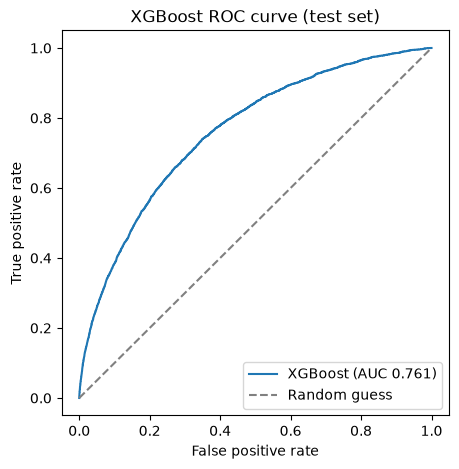

In [6]:
fig, ax = plt.subplots(figsize=(5, 5))
fpr, tpr, _ = roc_curve(y_test, p_test_raw)
ax.plot(fpr, tpr, label=f"XGBoost (AUC {auc_xgb:.3f})")
ax.plot([0, 1], [0, 1], "--", color="grey", label="Random guess")
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_title("XGBoost ROC curve (test set)"); ax.legend(loc="lower right")
fig.savefig(RESULTS / "xgb_roc.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Calibration

AUC only measures **ranking**. A lender also needs the probabilities themselves to be right, because they drive pricing and expected-loss estimates. Isotonic regression, fitted on the validation set, maps raw scores to probabilities that match observed default rates.

**Brier score** = mean squared error of the probabilities (lower is better).

Brier score, raw:        0.06726
Brier score, calibrated: 0.06733
AUC after calibration:   0.7600  (ranking is essentially unchanged)


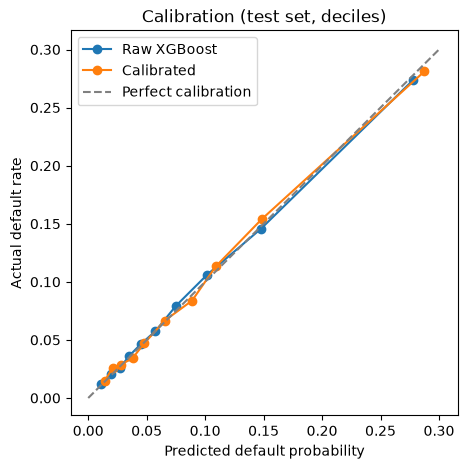

In [7]:
calibrator = IsotonicRegression(out_of_bounds="clip").fit(p_val_raw, y_val)
p_test = calibrator.predict(p_test_raw)

print(f"Brier score, raw:        {brier_score_loss(y_test, p_test_raw):.5f}")
print(f"Brier score, calibrated: {brier_score_loss(y_test, p_test):.5f}")
print(f"AUC after calibration:   {roc_auc_score(y_test, p_test):.4f}  (ranking is essentially unchanged)")

fig, ax = plt.subplots(figsize=(5, 5))
for probs, label in [(p_test_raw, "Raw XGBoost"), (p_test, "Calibrated")]:
    frac_pos, mean_pred = calibration_curve(y_test, probs, n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac_pos, marker="o", label=label)
lim = max(ax.get_xlim()[1], ax.get_ylim()[1])
ax.plot([0, lim], [0, lim], "--", color="grey", label="Perfect calibration")
ax.set_xlabel("Predicted default probability"); ax.set_ylabel("Actual default rate")
ax.set_title("Calibration (test set, deciles)"); ax.legend()
fig.savefig(RESULTS / "calibration.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Approval threshold

Approve an applicant if their predicted default probability is below a threshold. Where to set it depends on the cost of each mistake:
- **Approve someone who defaults:** the lender loses much of the loan.
- **Reject someone who would have repaid:** the lender loses the profit on that loan.

**Assumption:** a missed default costs **5×** a rejected good customer. That's a simplification for illustration: a real lender would plug in its own loss-given-default and margin figures. The threshold is chosen on the **validation** set, then reported on the test set.

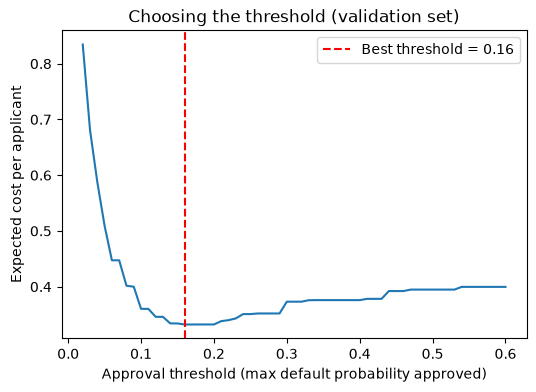

Threshold: approve if predicted default probability < 0.16
Approval rate:                    89.3%
Default rate if everyone approved: 8.03%
Default rate among approved:       5.81%
Share of defaulters caught:        35.4%


In [8]:
COST_BAD_APPROVED = 5.0   # approving a borrower who defaults
COST_GOOD_REJECTED = 1.0  # rejecting a borrower who would have repaid

def expected_cost(y_true, probs, threshold):
    approve = probs < threshold
    bad_approved = np.sum(approve & (y_true == 1))
    good_rejected = np.sum(~approve & (y_true == 0))
    return (COST_BAD_APPROVED * bad_approved + COST_GOOD_REJECTED * good_rejected) / len(y_true)

p_val = calibrator.predict(p_val_raw)
thresholds = np.linspace(0.02, 0.60, 59)
costs = [expected_cost(y_val.values, p_val, t) for t in thresholds]
best_t = float(thresholds[int(np.argmin(costs))])

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(thresholds, costs)
ax.axvline(best_t, color="red", linestyle="--", label=f"Best threshold = {best_t:.2f}")
ax.set_xlabel("Approval threshold (max default probability approved)")
ax.set_ylabel("Expected cost per applicant"); ax.set_title("Choosing the threshold (validation set)")
ax.legend()
fig.savefig(RESULTS / "threshold.png", dpi=150, bbox_inches="tight")
plt.show()

approve = p_test < best_t
print(f"Threshold: approve if predicted default probability < {best_t:.2f}")
print(f"Approval rate:                    {approve.mean():.1%}")
print(f"Default rate if everyone approved: {y_test.mean():.2%}")
print(f"Default rate among approved:       {y_test[approve].mean():.2%}")
print(f"Share of defaulters caught:        {(~approve & (y_test == 1)).sum() / (y_test == 1).sum():.1%}")

## 6. What drives XGBoost?

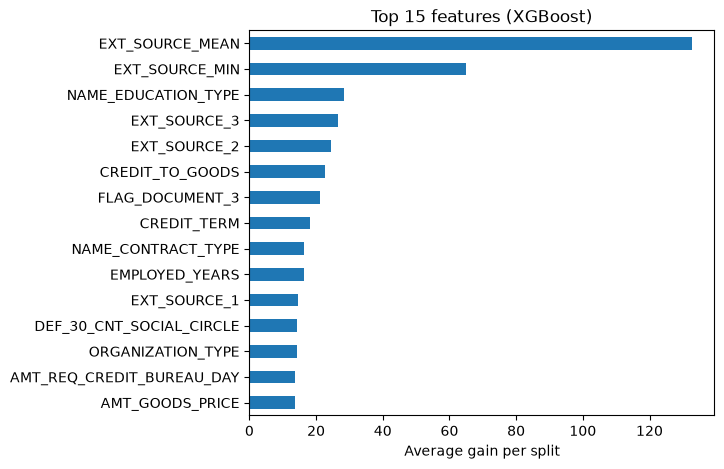

EXT_SOURCE_MEAN              132.8
EXT_SOURCE_MIN                65.1
NAME_EDUCATION_TYPE           28.5
EXT_SOURCE_3                  26.7
EXT_SOURCE_2                  24.5
CREDIT_TO_GOODS               22.6
FLAG_DOCUMENT_3               21.2
CREDIT_TERM                   18.3
NAME_CONTRACT_TYPE            16.4
EMPLOYED_YEARS                16.3
EXT_SOURCE_1                  14.4
DEF_30_CNT_SOCIAL_CIRCLE      14.3
ORGANIZATION_TYPE             14.3
AMT_REQ_CREDIT_BUREAU_DAY     13.7
AMT_GOODS_PRICE               13.6


In [9]:
imp = pd.Series(model.get_booster().get_score(importance_type="gain")).sort_values(ascending=False).head(15)
fig, ax = plt.subplots(figsize=(6, 5))
imp[::-1].plot.barh(ax=ax)
ax.set_xlabel("Average gain per split"); ax.set_title("Top 15 features (XGBoost)")
fig.savefig(RESULTS / "xgb_importance.png", dpi=150, bbox_inches="tight")
plt.show()
print(imp.round(1).to_string())

## 7. Save for deployment

In [10]:
model.save_model(MODELS / "xgb_model.json")
joblib.dump(calibrator, MODELS / "calibrator.joblib")
schema = {
    "features": list(X.columns),
    "categories": {c: [str(v) for v in X[c].cat.categories] for c in X.select_dtypes("category").columns},
    "threshold": best_t,
}
(MODELS / "schema.json").write_text(json.dumps(schema, indent=2))

metrics = {
    "model": "xgboost_calibrated",
    "test_auc": round(auc_xgb, 4), "test_gini": round(2 * auc_xgb - 1, 4),
    "baseline_auc": baseline["test_auc"],
    "brier_raw": round(brier_score_loss(y_test, p_test_raw), 5),
    "brier_calibrated": round(brier_score_loss(y_test, p_test), 5),
    "threshold": round(best_t, 2),
    "approval_rate": round(float(approve.mean()), 4),
    "default_rate_approved": round(float(y_test[approve].mean()), 4),
    "default_rate_all": round(float(y_test.mean()), 4),
    "best_trees": int(model.best_iteration + 1),
}
(RESULTS / "xgb_metrics.json").write_text(json.dumps(metrics, indent=2))
metrics

{'model': 'xgboost_calibrated',
 'test_auc': 0.7607,
 'test_gini': 0.5213,
 'baseline_auc': 0.7474,
 'brier_raw': 0.06726,
 'brier_calibrated': 0.06733,
 'threshold': 0.16,
 'approval_rate': 0.8926,
 'default_rate_approved': 0.0581,
 'default_rate_all': 0.0803,
 'best_trees': 693}

## Next step
Send back the **AUC comparison**, the **threshold results** and the **top features**. Step 3 explains individual decisions: for any applicant, which factors pushed their risk up or down (the "reason codes" lenders must give when they decline someone).